# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

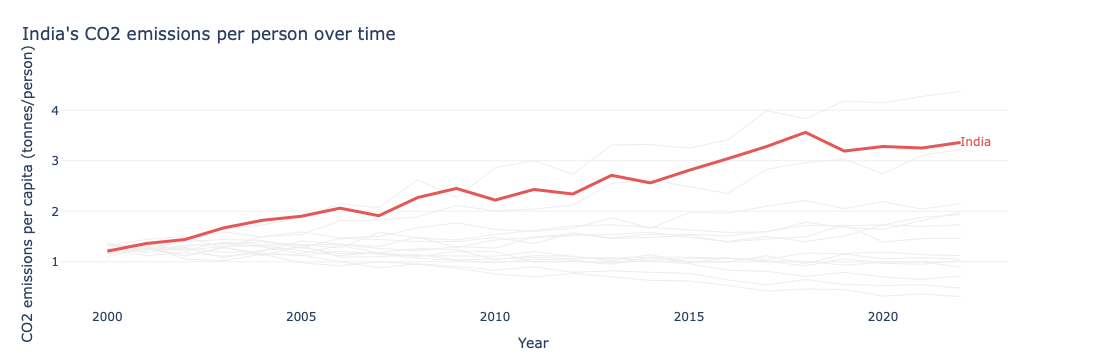

In [4]:

# Task 1: CO2 emissions per capita for all countries

# Find the per-capita column in the dataset
per_capita_cols = [
    col for col in df.columns
    if "per_capita" in col.lower().replace(" ", "_")
    or "per capita" in col.lower()
]

if per_capita_cols:
    y_col = per_capita_cols[0]
elif "Population" in df.columns:
    # CO2_Mt is in million tonnes; Population is number of people
    df["CO2_per_capita"] = df["CO2_Mt"] * 1_000_000 / df["Population"]
    y_col = "CO2_per_capita"
else:
    raise ValueError(
        "No CO2-per-capita or Population column found. "
        "Check df.columns and obtain a dataset with per-capita data."
    )

highlight_country = "India"

fig = go.Figure()

# Draw every other country in light grey
for country, data in df.groupby("Country"):
    data = data.sort_values("Year")

    if country == highlight_country:
        continue

    fig.add_trace(go.Scatter(
        x=data["Year"],
        y=data[y_col],
        mode="lines",
        line=dict(color="#EEEEEE", width=1),
        hovertemplate=f"{country}<br>Year: %{{x}}<br>CO2 per capita: %{{y:.2f}}<extra></extra>",
        showlegend=False
    ))

# Highlight India and label the last point directly
india = df[df["Country"] == highlight_country].sort_values("Year")

if india.empty:
    raise ValueError(f"{highlight_country} was not found in the dataset.")

fig.add_trace(go.Scatter(
    x=india["Year"],
    y=india[y_col],
    mode="lines+text",
    line=dict(color="#E45756", width=3),
    text=[""] * (len(india) - 1) + [highlight_country],
    textposition="middle right",
    textfont=dict(size=12, color="#E45756"),
    name=highlight_country,
    showlegend=False,
    hovertemplate="India<br>Year: %{x}<br>CO2 per capita: %{y:.2f}<extra></extra>"
))

fig.update_layout(
    title=dict(
        text="India's CO2 emissions per person over time",
        x=0.02,
        xanchor="left"
    ),
    xaxis_title="Year",
    yaxis_title="CO2 emissions per capita (tonnes/person)",
    template="plotly_white",
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False, zeroline=False)
fig.update_yaxes(showgrid=True, gridcolor="#F0F0F0",
                 showline=False, zeroline=False)

fig.show()


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

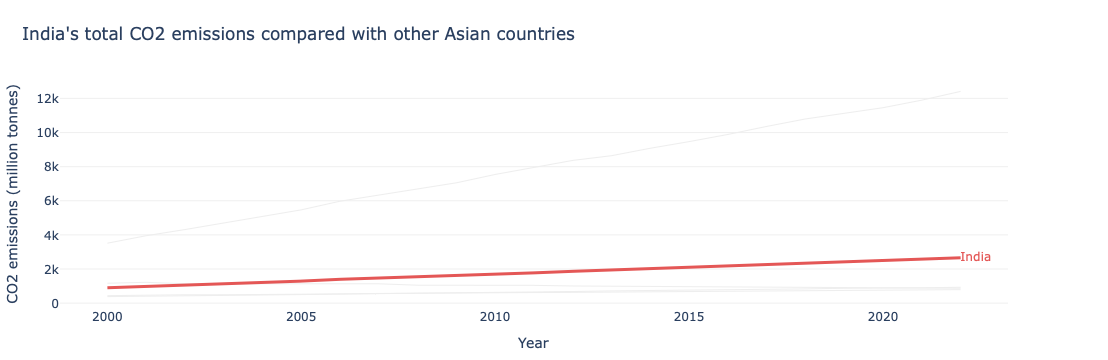

In [5]:
# Task — Multi-series line with highlight
# YOUR CODE HERE

# Task 2: CO2 emissions over time for Asian countries

highlight_country = "India"

# Select Asian countries
asia = df[df["Region"].str.strip().str.lower() == "asia"].copy()

if asia.empty:
    raise ValueError(
        "No rows found for Region='Asia'. "
        "Check the region names using df['Region'].unique()."
    )

fig = go.Figure()

# Draw other Asian countries in light grey
for country, data in asia.groupby("Country"):
    data = data.sort_values("Year")

    if country == highlight_country:
        continue

    fig.add_trace(go.Scatter(
        x=data["Year"],
        y=data["CO2_Mt"],
        mode="lines",
        line=dict(color="#EEEEEE", width=1),
        showlegend=False,
        hovertemplate=(
            f"{country}<br>Year: %{{x}}"
            "<br>CO2 emissions: %{y:.2f} Mt<extra></extra>"
        )
    ))

# Highlight India
india = asia[asia["Country"] == highlight_country].sort_values("Year")

if india.empty:
    raise ValueError(
        "India was not found among Asian countries. "
        "Check the Country and Region values."
    )

fig.add_trace(go.Scatter(
    x=india["Year"],
    y=india["CO2_Mt"],
    mode="lines+text",
    line=dict(color="#E45756", width=3),
    text=[""] * (len(india) - 1) + [highlight_country],
    textposition="middle right",
    textfont=dict(size=12, color="#E45756"),
    showlegend=False,
    hovertemplate=(
        "India<br>Year: %{x}"
        "<br>CO2 emissions: %{y:.2f} Mt<extra></extra>"
    )
))

fig.update_layout(
    title=dict(
        text="India's total CO2 emissions compared with other Asian countries",
        x=0.02,
        xanchor="left"
    ),
    xaxis_title="Year",
    yaxis_title="CO2 emissions (million tonnes)",
    template="plotly_white",
    plot_bgcolor="white",
    paper_bgcolor="white",
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False, zeroline=False)
fig.update_yaxes(showgrid=True, gridcolor="#F0F0F0",
                 showline=False, zeroline=False)

fig.show()
